# Taller práctico: Análisis de datos académicos con Pandas, NumPy y Matplotlib
**Aprendiz:** ________________  |  **Ficha / Grupo:** ________  |  **Fecha:** ________

Dataset: `data (1).csv` (4.424 estudiantes, 37 columnas). Ejecute las celdas en orden.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from google.colab import files

# Seleccionar y cargar el archivo CSV
archivos = files.upload()
nombre_archivo = next(iter(archivos))

# El archivo utiliza punto y coma como separador
df = pd.read_csv(nombre_archivo, sep=';')

# Ajustar nombres de columnas: quitar espacios y tabulaciones sobrantes
df.columns = df.columns.str.strip()

print("Archivo cargado correctamente")
print("Dimensiones:", df.shape)
display(df.head())

Archivo cargado correctamente
Dimensiones: (4424, 37)


,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,Mother's occupation,Father's occupation,Admission grade,Displaced,Educational special needs,Debtor,Tuition fees up to date,Gender,Scholarship holder,Age at enrollment,International,Curricular units 1st sem (credited),Curricular units 1st sem (enrolled),Curricular units 1st sem (evaluations),Curricular units 1st sem (approved),Curricular units 1st sem (grade),Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,5,9,127.3,1,0,0,1,1,0,20,0,0,0,0,0,0.000000,0,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,3,3,142.5,1,0,0,0,1,0,19,0,0,6,6,6,14.000000,0,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,9,9,124.8,1,0,0,0,1,0,19,0,0,6,0,0,0.000000,0,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,5,3,119.6,1,0,0,1,0,0,20,0,0,6,8,6,13.428571,0,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,9,9,141.5,0,0,0,1,0,0,45,0,0,6,9,5,12.333333,0,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


## Ejercicio 1. Lectura y exploración general del archivo

In [2]:
# 1. Primeros y últimos registros
display(df.head(10))
display(df.tail(5))

# 2. Dimensiones
filas, columnas = df.shape
print("Cantidad de estudiantes:", filas)
print("Cantidad de variables:", columnas)

# 3. Nombres y tipos de datos
print("\nInformación de las columnas:")
df.info()

# 4. Valores faltantes
print("\nValores nulos por columna:")
print(df.isnull().sum())

# 5. Estadísticas descriptivas
display(df.describe().round(2))

Cantidad de estudiantes: 4424
Cantidad de variables: 37

Información de las columnas:
<class 'pandas.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 37 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   Marital status                                  4424 non-null   int64  
 1   Application mode                                4424 non-null   int64  
 2   Application order                               4424 non-null   int64  
 3   Course                                          4424 non-null   int64  
 4   Daytime/evening attendance                      4424 non-null   int64  
 5   Previous qualification                          4424 non-null   int64  
 6   Previous qualification (grade)                  4424 non-null   float64
 7   Nacionality                                     4424 non-null   int64  
 8   Mother's qualification                     

,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,Mother's occupation,Father's occupation,Admission grade,Displaced,Educational special needs,Debtor,Tuition fees up to date,Gender,Scholarship holder,Age at enrollment,International,Curricular units 1st sem (credited),Curricular units 1st sem (enrolled),Curricular units 1st sem (evaluations),Curricular units 1st sem (approved),Curricular units 1st sem (grade),Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,5,9,127.3,1,0,0,1,1,0,20,0,0,0,0,0,0.000000,0,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,3,3,142.5,1,0,0,0,1,0,19,0,0,6,6,6,14.000000,0,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,9,9,124.8,1,0,0,0,1,0,19,0,0,6,0,0,0.000000,0,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,5,3,119.6,1,0,0,1,0,0,20,0,0,6,8,6,13.428571,0,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,9,9,141.5,0,0,0,1,0,0,45,0,0,6,9,5,12.333333,0,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate
5,2,39,1,9991,0,19,133.1,1,37,37,9,7,114.8,0,0,1,1,1,0,50,0,0,5,10,5,11.857143,0,0,5,17,5,11.500000,5,16.2,0.3,-0.92,Graduate
6,1,1,1,9500,1,1,142.0,1,19,38,7,10,128.4,1,0,0,1,0,1,18,0,0,7,9,7,13.300000,0,0,8,8,8,14.345000,0,15.5,2.8,-4.06,Graduate
7,1,18,4,9254,1,1,119.0,1,37,37,9,9,113.1,1,0,0,0,1,0,22,0,0,5,5,0,0.000000,0,0,5,5,0,0.000000,0,15.5,2.8,-4.06,Dropout
8,1,1,3,9238,1,1,137.0,62,1,1,9,9,129.3,0,0,0,1,0,1,21,1,0,6,8,6,13.875000,0,0,6,7,6,14.142857,0,16.2,0.3,-0.92,Graduate
9,1,1,1,9238,1,1,138.0,1,1,19,4,7,123.0,1,0,1,0,0,0,18,0,0,6,9,5,11.400000,0,0,6,14,2,13.500000,0,8.9,1.4,3.51,Dropout


,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,Mother's occupation,Father's occupation,Admission grade,Displaced,Educational special needs,Debtor,Tuition fees up to date,Gender,Scholarship holder,Age at enrollment,International,Curricular units 1st sem (credited),Curricular units 1st sem (enrolled),Curricular units 1st sem (evaluations),Curricular units 1st sem (approved),Curricular units 1st sem (grade),Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
4419,1,1,6,9773,1,1,125.0,1,1,1,5,4,122.2,0,0,0,1,1,0,19,0,0,6,7,5,13.600000,0,0,6,8,5,12.666667,0,15.5,2.8,-4.06,Graduate
4420,1,1,2,9773,1,1,120.0,105,1,1,9,9,119.0,1,0,1,0,0,0,18,1,0,6,6,6,12.000000,0,0,6,6,2,11.000000,0,11.1,0.6,2.02,Dropout
4421,1,1,1,9500,1,1,154.0,1,37,37,9,9,149.5,1,0,0,1,0,1,30,0,0,7,8,7,14.912500,0,0,8,9,1,13.500000,0,13.9,-0.3,0.79,Dropout
4422,1,1,1,9147,1,1,180.0,1,37,37,7,4,153.8,1,0,0,1,0,1,20,0,0,5,5,5,13.800000,0,0,5,6,5,12.000000,0,9.4,-0.8,-3.12,Graduate
4423,1,10,1,9773,1,1,152.0,22,38,37,5,9,152.0,1,0,0,1,0,0,22,1,0,6,8,6,11.666667,0,0,6,6,6,13.000000,0,12.7,3.7,-1.70,Graduate


,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,Mother's occupation,Father's occupation,Admission grade,Displaced,Educational special needs,Debtor,Tuition fees up to date,Gender,Scholarship holder,Age at enrollment,International,Curricular units 1st sem (credited),Curricular units 1st sem (enrolled),Curricular units 1st sem (evaluations),Curricular units 1st sem (approved),Curricular units 1st sem (grade),Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP
count,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00
mean,1.18,18.67,1.73,8856.64,0.89,4.58,132.61,1.87,19.56,22.28,10.96,11.03,126.98,0.55,0.01,0.11,0.88,0.35,0.25,23.27,0.02,0.71,6.27,8.30,4.71,10.64,0.14,0.54,6.23,8.06,4.44,10.23,0.15,11.57,1.23,0.00
std,0.61,17.48,1.31,2063.57,0.31,10.22,13.19,6.91,15.60,15.34,26.42,25.26,14.48,0.50,0.11,0.32,0.32,0.48,0.43,7.59,0.16,2.36,2.48,4.18,3.09,4.84,0.69,1.92,2.20,3.95,3.01,5.21,0.75,2.66,1.38,2.27
min,1.00,1.00,0.00,33.00,0.00,1.00,95.00,1.00,1.00,1.00,0.00,0.00,95.00,0.00,0.00,0.00,0.00,0.00,0.00,17.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,7.60,-0.80,-4.06
25%,1.00,1.00,1.00,9085.00,1.00,1.00,125.00,1.00,2.00,3.00,4.00,4.00,117.90,0.00,0.00,0.00,1.00,0.00,0.00,19.00,0.00,0.00,5.00,6.00,3.00,11.00,0.00,0.00,5.00,6.00,2.00,10.75,0.00,9.40,0.30,-1.70
50%,1.00,17.00,1.00,9238.00,1.00,1.00,133.10,1.00,19.00,19.00,5.00,7.00,126.10,1.00,0.00,0.00,1.00,0.00,0.00,20.00,0.00,0.00,6.00,8.00,5.00,12.29,0.00,0.00,6.00,8.00,5.00,12.20,0.00,11.10,1.40,0.32
75%,1.00,39.00,2.00,9556.00,1.00,1.00,140.00,1.00,37.00,37.00,9.00,9.00,134.80,1.00,0.00,0.00,1.00,1.00,0.00,25.00,0.00,0.00,7.00,10.00,6.00,13.40,0.00,0.00,7.00,10.00,6.00,13.33,0.00,13.90,2.60,1.79
max,6.00,57.00,9.00,9991.00,1.00,43.00,190.00,109.00,44.00,44.00,194.00,195.00,190.00,1.00,1.00,1.00,1.00,1.00,1.00,70.00,1.00,20.00,26.00,45.00,26.00,18.88,12.00,19.00,23.00,33.00,20.00,18.57,12.00,16.20,3.70,3.51


### Respuestas – Ejercicio 1
- **¿Cuántos estudiantes y variables?** 4.424 estudiantes (filas) y 37 variables (columnas).
- **Numérica vs. texto:** una variable numérica (p. ej. `Age at enrollment`) permite operar matemáticamente (promedio, desviación, correlación). Una de texto (`Target`) es categórica: solo se puede contar, agrupar o usar para comparar grupos. Ojo: códigos como `Course` o `Application mode` son numéricos pero representan *categorías*, así que su promedio no tiene sentido.
- **Valores nulos:** no hay ninguno (0 nulos en las 37 columnas). Si existieran, se podría eliminar la fila (si son pocas), imputar con media/mediana (numéricas) o moda (categóricas), o analizar por qué faltan, y documentar siempre la decisión.

## Ejercicio 2. Estadística descriptiva con NumPy

In [3]:
# Convertir columnas de Pandas en arreglos NumPy
edades = df['Age at enrollment'].to_numpy()
notas_admision = df['Admission grade'].to_numpy()

# Estadísticas de edad
print("EDAD")
print("Promedio:", round(np.mean(edades), 2))
print("Mediana:", np.median(edades))
print("Mínimo:", np.min(edades))
print("Máximo:", np.max(edades))
print("Desviación estándar:", round(np.std(edades), 2))

# Filtros booleanos con NumPy
print("Mayores de 25 años:", np.sum(edades > 25))
print("Menores de 20 años:", np.sum(edades < 20))

# Estadísticas de calificación de admisión
print("\nCALIFICACIÓN DE ADMISIÓN")
print("Promedio:", round(np.mean(notas_admision), 2))
print("Desviación estándar:", round(np.std(notas_admision), 2))
print("Mínimo:", np.min(notas_admision))
print("Máximo:", np.max(notas_admision))

EDAD
Promedio: 23.27
Mediana: 20.0
Mínimo: 17
Máximo: 70
Desviación estándar: 7.59
Mayores de 25 años: 1045
Menores de 20 años: 1952

CALIFICACIÓN DE ADMISIÓN
Promedio: 126.98
Desviación estándar: 14.48
Mínimo: 95.0
Máximo: 190.0


### Respuestas – Ejercicio 2
- **Mediana de edad (20 años):** es el valor central: la mitad de los estudiantes tiene 20 años o menos y la otra mitad 20 o más.
- **¿Por qué promedio (23,27) ≠ mediana (20)?** La distribución está sesgada a la derecha: hay pocos estudiantes mayores (hasta 70 años) que "jalan" el promedio hacia arriba, mientras que la mediana es resistente a valores extremos.
- **Desviación estándar (≈7,59 años en edad; ≈14,48 en admisión):** mide cuánto se dispersan los datos alrededor del promedio. En edad es alta respecto al promedio, lo que confirma un grupo heterogéneo con muchos estudiantes jóvenes y una cola de adultos.

## Ejercicio 3. Distribución de los resultados académicos

In [4]:
# Conteo por categoría con Pandas
conteo = df['Target'].value_counts()
print("Cantidad por resultado:")
print(conteo)

# Porcentajes con NumPy
total = len(df)
porcentajes = (conteo.to_numpy() / total) * 100

resumen = pd.DataFrame({
    'Cantidad': conteo,
    'Porcentaje': porcentajes
})
display(resumen.round(2))

# Edad promedio por resultado
edad_por_resultado = df.groupby('Target')['Age at enrollment'].mean()
print("\nEdad promedio por resultado:")
print(edad_por_resultado.round(2))

print("\nGrupo con mayor edad promedio:",
      edad_por_resultado.idxmax())

Cantidad por resultado:
Target
Graduate    2209
Dropout     1421
Enrolled     794
Name: count, dtype: int64

Edad promedio por resultado:
Target
Dropout     26.07
Enrolled    22.37
Graduate    21.78
Name: Age at enrollment, dtype: float64

Grupo con mayor edad promedio: Dropout


,Cantidad,Porcentaje
Target,,
Graduate,2209,49.93
Dropout,1421,32.12
Enrolled,794,17.95


### Respuestas – Ejercicio 3
- **Mayor cantidad:** *Graduate* (2.209 estudiantes, 49,93 %).
- **Porcentaje de Dropout:** 32,12 % (1.421 estudiantes).
- **Edad promedio por grupo:** Dropout 26,07 · Enrolled 22,37 · Graduate 21,78. Quienes desertan ingresaron, en promedio, unos 4 años mayores que quienes se graduaron. Es una asociación, no prueba que la edad cause la deserción (pueden influir trabajo, familia, etc.).

## Ejercicio 4. Comparación del rendimiento académico por semestre

In [5]:
col_nota_1 = 'Curricular units 1st sem (grade)'
col_nota_2 = 'Curricular units 2nd sem (grade)'
col_aprobadas_1 = 'Curricular units 1st sem (approved)'
col_aprobadas_2 = 'Curricular units 2nd sem (approved)'

nota_1 = df[col_nota_1].to_numpy()
nota_2 = df[col_nota_2].to_numpy()

print("Promedio general primer semestre:", round(np.mean(nota_1), 2))
print("Promedio general segundo semestre:", round(np.mean(nota_2), 2))

# Comparación de promedios por resultado
comparacion = df.groupby('Target')[
    [col_nota_1, col_nota_2, col_aprobadas_1, col_aprobadas_2]
].mean()

display(comparacion.round(2))

# Diferencia individual entre semestres
df['Diferencia_notas'] = df[col_nota_2] - df[col_nota_1]
diferencias = df['Diferencia_notas'].to_numpy()

print("Mejoraron:", np.sum(diferencias > 0))
print("Disminuyeron:", np.sum(diferencias < 0))
print("Mantuvieron:", np.sum(diferencias == 0))

Promedio general primer semestre: 10.64
Promedio general segundo semestre: 10.23
Mejoraron: 1554
Disminuyeron: 1721
Mantuvieron: 1149


,Curricular units 1st sem (grade),Curricular units 2nd sem (grade),Curricular units 1st sem (approved),Curricular units 2nd sem (approved)
Target,,,,
Dropout,7.26,5.90,2.55,1.94
Enrolled,11.13,11.12,4.32,4.06
Graduate,12.64,12.70,6.23,6.18


### Respuestas – Ejercicio 4
- **Mayor promedio de calificaciones:** *Graduate* (12,64 en el 1.er sem. y 12,70 en el 2.º).
- **Promedio general:** el del 2.º semestre (10,23) es **menor** que el del 1.º (10,64).
- **Mejoraron / disminuyeron / mantuvieron:** 1.554 / 1.721 / 1.149. Los 1.149 que "mantuvieron" incluyen muchos con nota 0 en ambos semestres (676 estudiantes), que probablemente no fueron evaluados.
- **Limitaciones de comparar solo promedios:** ocultan la dispersión y los valores atípicos; los ceros (sin evaluación) bajan el promedio; no consideran cuántas asignaturas cursó cada estudiante; y no indican causalidad.

## Ejercicio 5. Estado de matrícula y becas

In [6]:
# Conteos mediante NumPy
matricula = df['Tuition fees up to date'].to_numpy()
beca = df['Scholarship holder'].to_numpy()

al_dia = np.sum(matricula == 1)
pendiente = np.sum(matricula == 0)

print("Matrícula al día:", al_dia)
print("Matrícula pendiente:", pendiente)
print("Porcentaje al día:", round(al_dia / len(df) * 100, 2), "%")
print("Porcentaje pendiente:", round(pendiente / len(df) * 100, 2), "%")

print("\nEstudiantes con beca:", np.sum(beca == 1))
print("Estudiantes sin beca:", np.sum(beca == 0))

# Tablas cruzadas con Pandas
print("\nMatrícula frente a resultado:")
display(pd.crosstab(df['Tuition fees up to date'], df['Target']))

print("\nBeca frente a resultado:")
display(pd.crosstab(df['Scholarship holder'], df['Target']))

# Complemento: porcentajes por fila (más fácil de comparar)
print("\nMatrícula frente a resultado (% por fila):")
display((pd.crosstab(df['Tuition fees up to date'], df['Target'], normalize='index') * 100).round(1))
print("\nBeca frente a resultado (% por fila):")
display((pd.crosstab(df['Scholarship holder'], df['Target'], normalize='index') * 100).round(1))

Matrícula al día: 3896
Matrícula pendiente: 528
Porcentaje al día: 88.07 %
Porcentaje pendiente: 11.93 %

Estudiantes con beca: 1099
Estudiantes sin beca: 3325

Matrícula frente a resultado:

Beca frente a resultado:

Matrícula frente a resultado (% por fila):

Beca frente a resultado (% por fila):


Target,Dropout,Enrolled,Graduate
Tuition fees up to date,,,
0,457,42,29
1,964,752,2180


Target,Dropout,Enrolled,Graduate
Scholarship holder,,,
0,1287,664,1374
1,134,130,835


Target,Dropout,Enrolled,Graduate
Tuition fees up to date,,,
0,86.6,8.0,5.5
1,24.7,19.3,56.0


Target,Dropout,Enrolled,Graduate
Scholarship holder,,,
0,38.7,20.0,41.3
1,12.2,11.8,76.0


### Respuestas – Ejercicio 5
- **Matrícula pendiente:** 528 estudiantes (11,94 %); al día: 3.896 (88,06 %).
- **Resultado más frecuente con matrícula pendiente:** *Dropout* (457 de 528 = 86,6 %). Entre quienes están al día, Dropout es 24,7 % y Graduate 56,0 %.
- **Beca vs. sin beca:** 1.099 con beca y 3.325 sin beca. Entre becarios, 76,0 % son Graduate y 12,2 % Dropout; entre no becarios, 41,3 % Graduate y 38,7 % Dropout.
- **Cuidado al interpretar:** son asociaciones. Que la matrícula pendiente coincida con la deserción no demuestra que sea la causa (puede ser consecuencia: quien abandona deja de pagar), y los becarios pueden diferir en otros aspectos (p. ej. mérito académico).

## Ejercicio 6. Visualización de datos con Matplotlib

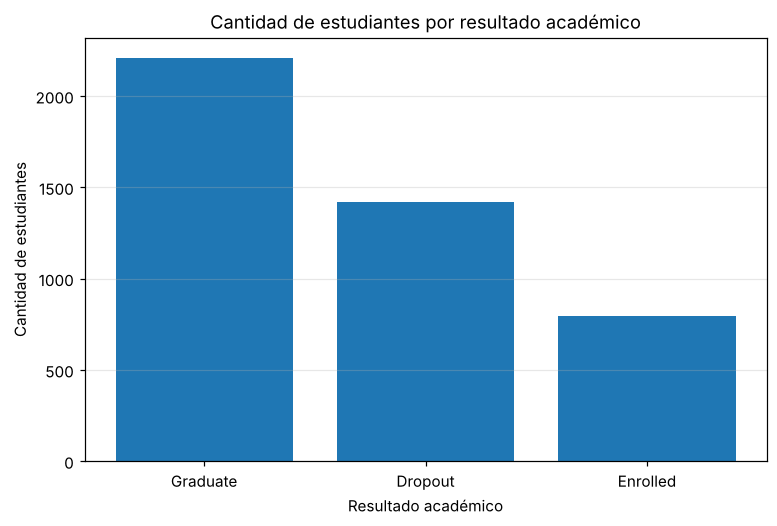

In [7]:
# Gráfico 1: cantidad de estudiantes por resultado
conteo = df['Target'].value_counts()

plt.figure(figsize=(8, 5))
plt.bar(conteo.index, conteo.values)
plt.title('Cantidad de estudiantes por resultado académico')
plt.xlabel('Resultado académico')
plt.ylabel('Cantidad de estudiantes')
plt.grid(axis='y', alpha=0.3)
plt.show()

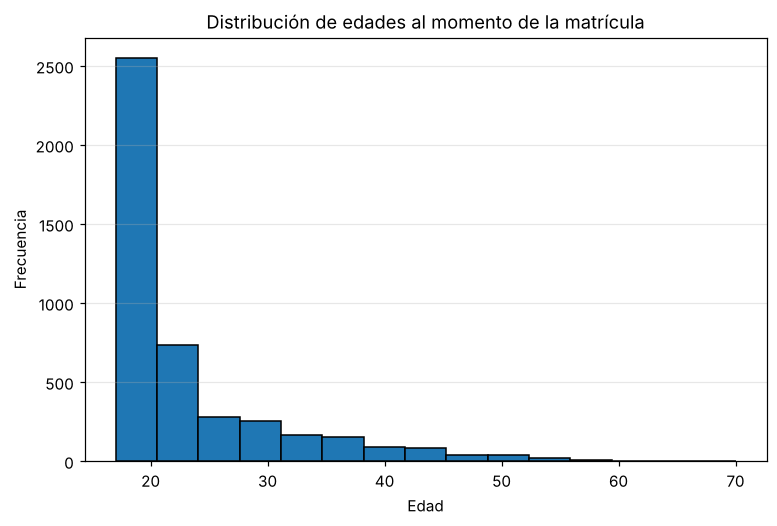

In [8]:
# Gráfico 2: distribución de edades
plt.figure(figsize=(8, 5))
plt.hist(df['Age at enrollment'], bins=15, edgecolor='black')
plt.title('Distribución de edades al momento de la matrícula')
plt.xlabel('Edad')
plt.ylabel('Frecuencia')
plt.grid(axis='y', alpha=0.3)
plt.show()

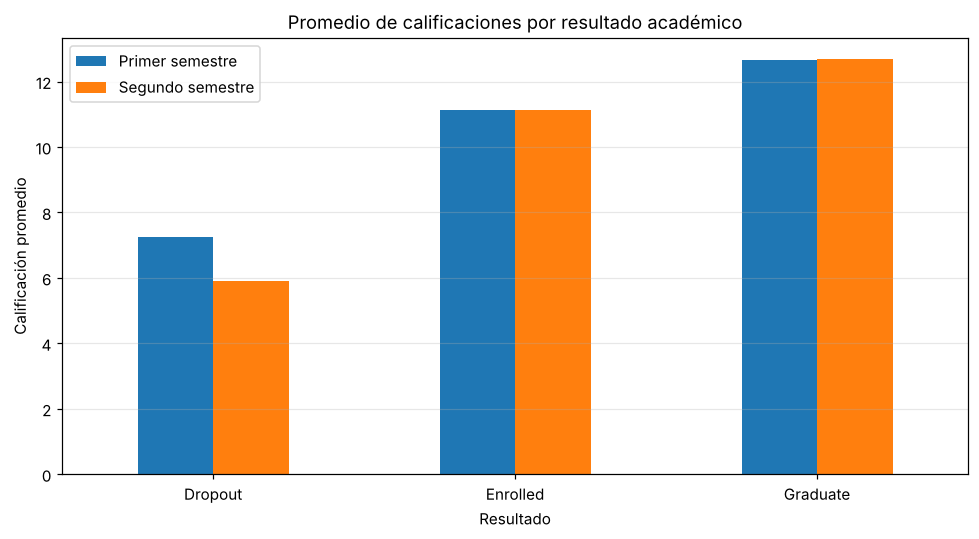

In [9]:
# Gráfico 3: promedio de notas por resultado y semestre
promedios = df.groupby('Target')[
    ['Curricular units 1st sem (grade)',
     'Curricular units 2nd sem (grade)']
].mean()

promedios.plot(kind='bar', figsize=(9, 5))
plt.title('Promedio de calificaciones por resultado académico')
plt.xlabel('Resultado')
plt.ylabel('Calificación promedio')
plt.xticks(rotation=0)
plt.legend(['Primer semestre', 'Segundo semestre'])
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

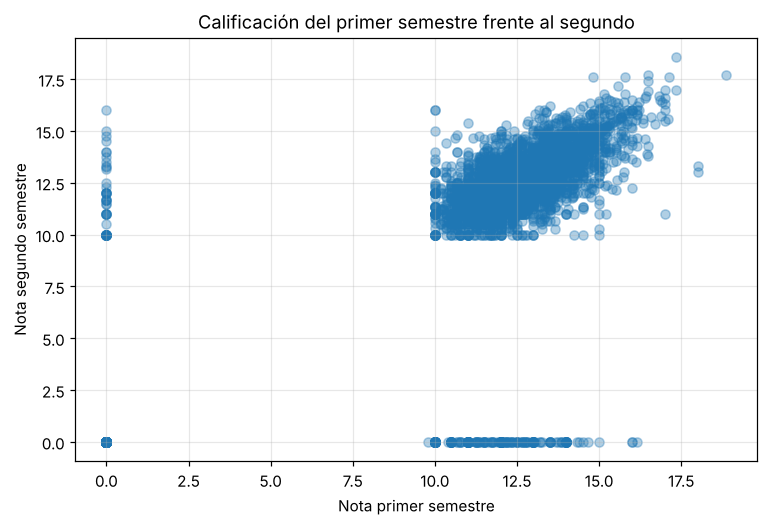

In [10]:
# Gráfico 4: relación entre calificaciones de los dos semestres
plt.figure(figsize=(8, 5))
plt.scatter(
    df['Curricular units 1st sem (grade)'],
    df['Curricular units 2nd sem (grade)'],
    alpha=0.35
)
plt.title('Calificación del primer semestre frente al segundo')
plt.xlabel('Nota primer semestre')
plt.ylabel('Nota segundo semestre')
plt.grid(alpha=0.3)
plt.show()

### Respuestas – Ejercicio 6
- **Barra más alta:** *Graduate* (2.209).
- **Rango de edades más concentrado:** entre 17 y 21 años (≈2.550 estudiantes en el primer intervalo del histograma, 17–20,5); la frecuencia cae rápidamente con la edad (cola larga hacia 70).
- **Patrón en la dispersión:** relación positiva y fuerte (r ≈ 0,84): quien tiene buena nota en el 1.er semestre tiende a tenerla en el 2.º. Se aprecia además un grupo de puntos en 0 (estudiantes sin notas), sobre los ejes.
- **Mejor gráfico para comunicar un hallazgo:** el de barras agrupadas de notas por resultado (Gráfico 3), porque en una sola mirada muestra que *Graduate* y *Enrolled* mantienen sus notas mientras *Dropout* tiene notas más bajas y cae del 1.er al 2.º semestre (7,26 → 5,90). (Otra respuesta válida es justificarla con el dato que usted considere más claro.)

## Ejercicio 7. Miniinforme: factores asociados al resultado académico

In [11]:
variables = [
    'Age at enrollment',
    'Admission grade',
    'Curricular units 1st sem (grade)',
    'Curricular units 1st sem (approved)',
    'Curricular units 2nd sem (grade)',
    'Curricular units 2nd sem (approved)'
]

# Seleccionar variables y calcular correlaciones con Pandas
matriz_corr = df[variables].corr()
display(matriz_corr.round(2))

# Correlación específica con NumPy
nota_1 = df['Curricular units 1st sem (grade)'].to_numpy()
nota_2 = df['Curricular units 2nd sem (grade)'].to_numpy()

corr_numpy = np.corrcoef(nota_1, nota_2)[0, 1]
print("Correlación entre notas de ambos semestres:",
      round(corr_numpy, 4))

Correlación entre notas de ambos semestres: 0.8372


,Age at enrollment,Admission grade,Curricular units 1st sem (grade),Curricular units 1st sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (approved)
Age at enrollment,1.00,-0.03,-0.16,-0.05,-0.17,-0.11
Admission grade,-0.03,1.00,0.07,0.07,0.07,0.08
Curricular units 1st sem (grade),-0.16,0.07,1.00,0.70,0.84,0.67
Curricular units 1st sem (approved),-0.05,0.07,0.70,1.00,0.69,0.90
Curricular units 2nd sem (grade),-0.17,0.07,0.84,0.69,1.00,0.76
Curricular units 2nd sem (approved),-0.11,0.08,0.67,0.90,0.76,1.00


,estudiantes,edad_promedio,nota_semestre_1,nota_semestre_2,aprobadas_semestre_1,aprobadas_semestre_2
Target,,,,,,
Dropout,1421,26.07,7.26,5.90,2.55,1.94
Enrolled,794,22.37,11.13,11.12,4.32,4.06
Graduate,2209,21.78,12.64,12.70,6.23,6.18


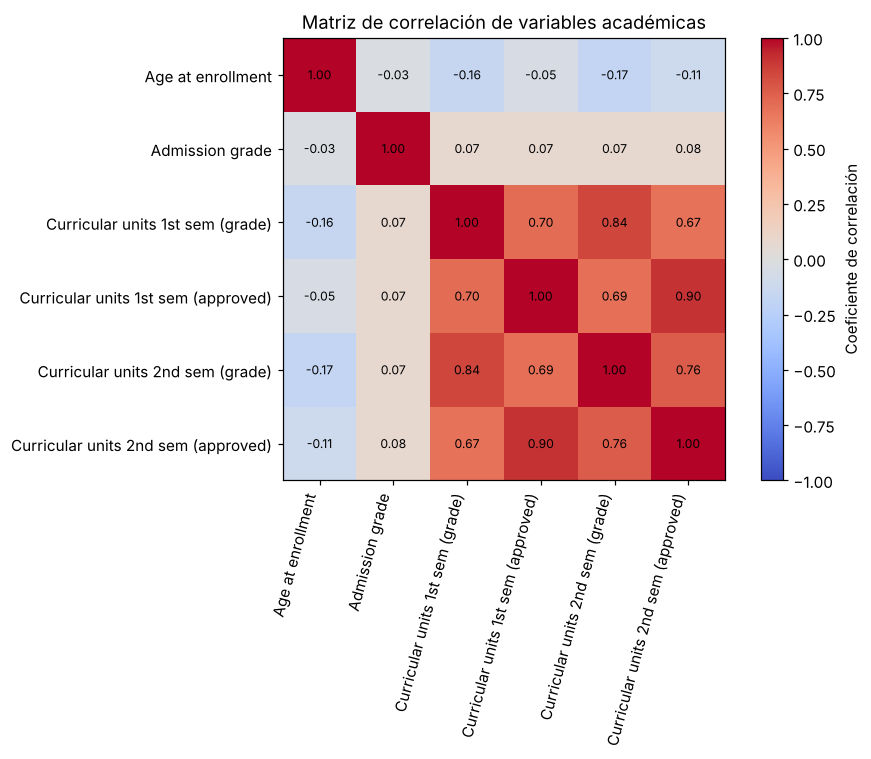

In [12]:
# Visualizar la matriz de correlación usando Matplotlib
plt.figure(figsize=(9, 7))
plt.imshow(matriz_corr, cmap='coolwarm', vmin=-1, vmax=1)
plt.colorbar(label='Coeficiente de correlación')
plt.xticks(range(len(variables)), variables, rotation=75, ha='right')
plt.yticks(range(len(variables)), variables)

for i in range(len(variables)):
    for j in range(len(variables)):
        plt.text(j, i, f'{matriz_corr.iloc[i, j]:.2f}',
                 ha='center', va='center', fontsize=8)

plt.title('Matriz de correlación de variables académicas')
plt.tight_layout()
plt.show()

# Resumen por resultado académico
resumen_final = df.groupby('Target').agg(
    estudiantes=('Target', 'size'),
    edad_promedio=('Age at enrollment', 'mean'),
    nota_semestre_1=('Curricular units 1st sem (grade)', 'mean'),
    nota_semestre_2=('Curricular units 2nd sem (grade)', 'mean'),
    aprobadas_semestre_1=('Curricular units 1st sem (approved)', 'mean'),
    aprobadas_semestre_2=('Curricular units 2nd sem (approved)', 'mean')
)

display(resumen_final.round(2))

# Miniinforme: factores asociados al resultado académico

## 1. Introducción
El conjunto de datos reúne a 4.424 estudiantes con 37 variables demográficas, de admisión, socioeconómicas y de desempeño en los dos primeros semestres. La variable `Target` clasifica a cada estudiante como *Graduate* (49,9 %), *Dropout* (32,1 %) o *Enrolled* (17,9 %). El archivo no tiene valores nulos. El análisis es exploratorio y describe asociaciones del archivo analizado, no causas.

## 2. Indicadores principales por Target
| Target | Estudiantes | Edad prom. | Nota 1.er sem. | Nota 2.º sem. | Aprobadas 1.er sem. | Aprobadas 2.º sem. |
|---|---|---|---|---|---|---|
| Dropout | 1.421 | 26,07 | 7,26 | 5,90 | 2,55 | 1,94 |
| Enrolled | 794 | 22,37 | 11,13 | 11,12 | 4,32 | 4,06 |
| Graduate | 2.209 | 21,78 | 12,64 | 12,70 | 6,23 | 6,18 |

## 3. Matriz de correlación
Ver el gráfico generado arriba (también guardado en `graficos/07_matriz_correlacion.png`). Las correlaciones más altas son: aprobadas 1.er sem. ↔ aprobadas 2.º sem. (0,90), nota 1.er sem. ↔ nota 2.º sem. (0,84) y nota 2.º sem. ↔ aprobadas 2.º sem. (0,76). La nota de admisión casi no se relaciona con el rendimiento posterior (≈0,07).

## 4. Cinco hallazgos
1. **Graduate es el grupo mayoritario (49,9 %), pero 1 de cada 3 estudiantes (32,1 %, 1.421) aparece como Dropout.**
2. **El rendimiento del primer año distingue fuertemente a los grupos:** Dropout promedia 2,55 y 1,94 asignaturas aprobadas por semestre frente a 6,23 y 6,18 en Graduate; las notas medias son 7,26/5,90 frente a 12,64/12,70.
3. **El rendimiento es muy persistente entre semestres:** la correlación entre notas es 0,8372 y entre asignaturas aprobadas 0,90. Quien rinde mal en el 1.er semestre suele seguir igual, lo que permite detectar riesgo temprano.
4. **Matrícula pendiente y becas se asocian con el resultado:** con matrícula pendiente, 86,6 % (457 de 528) son Dropout, frente a 24,7 % con matrícula al día; entre becarios, 76,0 % son Graduate y 12,2 % Dropout, frente a 41,3 % y 38,7 % entre no becarios.
5. **La edad se asocia con la deserción, la nota de admisión poco:** Dropout ingresa con 26,07 años en promedio (Graduate 21,78) y la correlación edad–nota es negativa y débil (−0,16/−0,17); la nota de admisión difiere poco entre grupos (124,96 Dropout vs. 128,79 Graduate).

## 5. Recomendaciones / preguntas para investigación posterior
- **Sistema de alerta temprana:** estudiar si el número de asignaturas aprobadas en el 1.er semestre (y el pago de matrícula) permite predecir la deserción con antelación, y evaluar apoyos (tutorías, becas, planes de pago) para estudiantes en riesgo.
- **Preguntas abiertas:** ¿la asociación de las becas con la graduación se mantiene al controlar por nota de admisión, edad, curso y situación socioeconómica? ¿Qué ocurre con los 676 estudiantes con nota 0 en ambos semestres (546 Dropout)? ¿Son abandonos tempranos?

**Limitaciones:** los datos son de una institución y cohorte concretas; las correlaciones miden asociación lineal y no demuestran causalidad.